# TB chest X-ray screening: a model that works, until it moves

**The setting.** A TB programme screens adults with a chest X-ray. Anyone the model flags is
sent for a lab test (e.g. GeneXpert). A **missed TB case** goes home untreated and keeps
transmitting; a **false alarm** costs a lab test. The programme wants to catch at least 90%
of TB cases (WHO's target for computer-aided detection is ≥ 90% sensitivity and ≥ 70% specificity).

**The data.** Real, de-identified chest X-rays from two public datasets, standing in for two hospitals:

| | Site A | Site B |
|---|---|---|
| Source | TBX11K (hospitals in China) | Kiran & Jabeen (a hospital in Pakistan) |
| Images here | 200 TB + 200 normal | 200 TB + 200 normal |
| Used for | building the first model | the new site we expand to |
| Licence | CC BY 4.0 | CC BY 4.0 |

All images are resized to 224 × 224 grayscale. Real screening populations are mostly
healthy (TB in 1–5% of those screened), not 50%; we come back to that in part 6.

**The story, in six beats:** a first model at site A looks excellent (parts 1–3) → it is
deployed at site B and quietly fails (part 4) → a second team builds a model that learns
the hospital instead of the disease (part 5) → what the numbers mean for a real programme (part 6).

In [1]:
import os
import warnings

warnings.filterwarnings("ignore")
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"      # keep MLflow's import message out of the output
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from mlflow.models import infer_signature
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import tb_helpers as tb

pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 3)
meta, X = tb.load_data()          # one row per image, and its 1024 image features (precomputed)
y = meta.tb.to_numpy()            # 1 = TB, 0 = normal


def rows(**conditions):
    """Positions of the images matching e.g. site='A', split='train'."""
    keep = np.ones(len(meta), bool)
    for col, val in conditions.items():
        keep &= meta[col].to_numpy() == val
    return np.flatnonzero(keep)


A_train, A_test = rows(site="A", split="train"), rows(site="A", split="test")
B_sample, B_test = rows(site="B", split="local_sample"), rows(site="B", split="test")
meta.groupby(["site", "split", "tb"]).size().unstack("tb").rename(columns={0: "normal", 1: "TB"})

tb                 normal   TB
site split                    
A    test              50   50
     train            150  150
B    local_sample      25   25
     test             175  175

## 1. Look at the data

Always look before modelling. Can you see a difference between the sites? Between TB and normal?
(Look at the corners: site B's images carry burned-in letters and numbers, site A's have black
borders. Neither has anything to do with TB, and a model can still learn from them.)

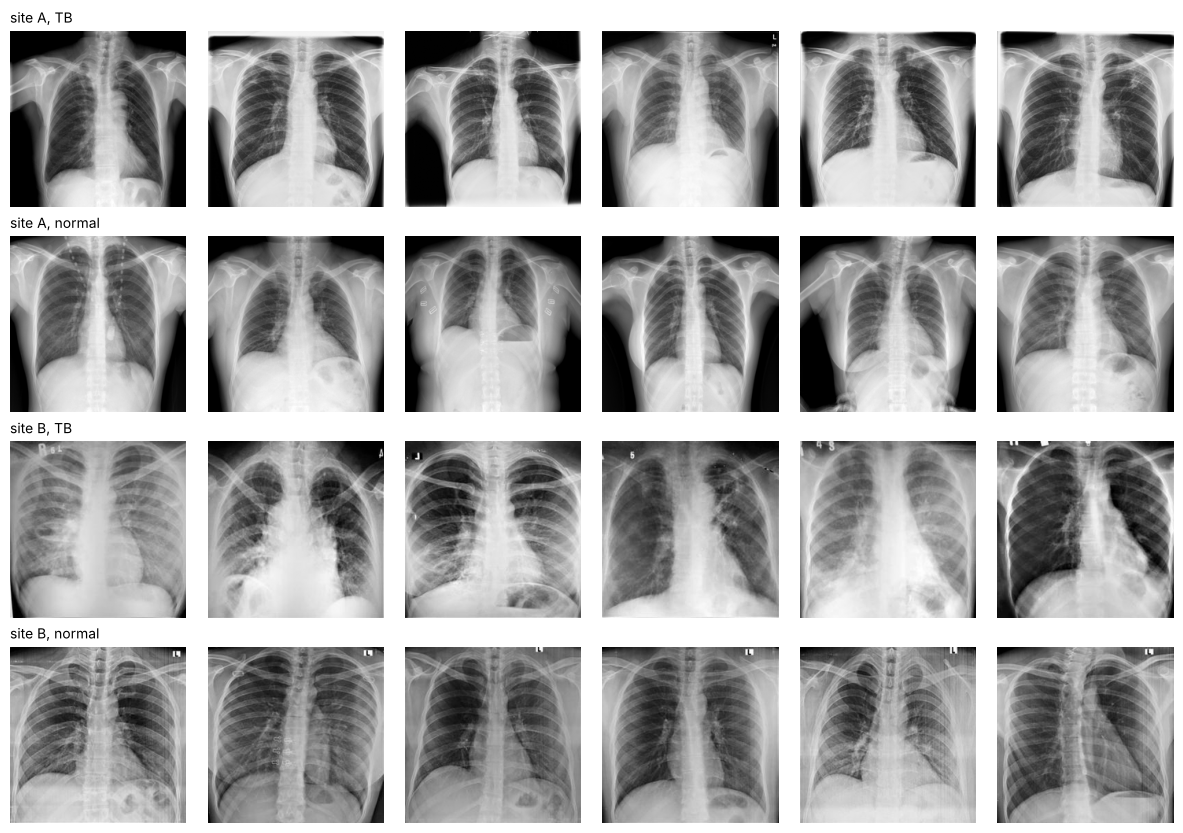

In [2]:
fig, axes = plt.subplots(4, 6, figsize=(12, 8.4))
for r, (site, label) in enumerate([("A", 1), ("A", 0), ("B", 1), ("B", 0)]):
    for c, path in enumerate(meta.path[(meta.site == site) & (meta.tb == label)].head(6)):
        axes[r, c].imshow(Image.open(path), cmap="gray")
        axes[r, c].set_axis_off()
    axes[r, 0].set_title(f"site {site}, {'TB' if label else 'normal'}", loc="left", fontsize=10)
plt.tight_layout()

## 2. Image checks: the Great Expectations idea, for images

For tables, Great Expectations checks columns ("MUAC between 8 and 25 cm"). For images, we
compute a few facts per file (size, colour mode, brightness, contrast, share of pure-black
pixels) and write rules from a **reference**: the images the model was trained on.
These checks run on every incoming batch, before the model.

In [3]:
checks = tb.image_checks(meta.path)
checks.insert(0, "site", meta.site.to_numpy())
reference = checks.iloc[A_train]


def image_rules(batch, ref=reference):
    """Share of images in `batch` that break each rule (rules learned from the reference)."""
    lo, hi = ref[["mean", "std", "pct_black"]].quantile(0.01), ref[["mean", "std", "pct_black"]].quantile(0.99)
    return pd.Series({
        "size is 224 x 224": ((batch.width != 224) | (batch.height != 224)).mean(),
        "grayscale": (batch["mode"] != "L").mean(),
        "brightness in reference range": (~batch["mean"].between(lo["mean"], hi["mean"])).mean(),
        "contrast in reference range": (~batch["std"].between(lo["std"], hi["std"])).mean(),
        "black border in reference range": (~batch.pct_black.between(lo.pct_black, hi.pct_black)).mean(),
    }, name="share failing")


pd.DataFrame({"site A (new test images)": image_rules(checks.iloc[A_test]),
              "site B (first batch)": image_rules(checks.iloc[B_test])})

,site A (new test images),site B (first batch)
size is 224 x 224,0.00,0.000
grayscale,0.00,0.000
brightness in reference range,0.02,0.043
contrast in reference range,0.01,0.586
black border in reference range,0.02,0.457


In [4]:
checks.groupby("site")[["mean", "std", "pct_black"]].describe().T.loc[(slice(None), ["25%", "50%", "75%"]), :]

site                 A        B
mean      25%  115.170  124.662
          50%  129.420  134.589
          75%  139.560  145.363
std       25%   62.611   45.671
          50%   67.194   50.245
          75%   71.778   55.525
pct_black 25%    5.367    0.002
          50%    9.162    0.059
          75%   13.509    0.430

**Site B's images are different before any model sees them:** lower contrast and almost no
black border (site A's images include the black edge of the detector; site B's were cropped).
None of these is an *error* like a corrupted file: the batch should not be blocked, but someone
should be told **"these images don't look like the training data; check the model here before trusting it."**

## 3. A first model at site A

**Features.** Training an image network from scratch needs tens of thousands of images and a GPU.
Instead we use a network **already trained on other chest X-ray collections** (torchxrayvision's
DenseNet; none of our TB images were in its training data) to turn each image into 1024 numbers,
and train a small logistic regression on those. The features are precomputed in `data/embeddings.npz`;
the optional cell below recomputes some on your laptop if the model file is present (see README).

In [5]:
if tb.MODEL_FILE.exists():
    sample = meta.path.iloc[:8].tolist()
    fresh = tb.embed(sample)
    print("recomputed 8 images; largest difference from the stored features:", float(np.abs(fresh - X[:8]).max()))
else:
    print("model file not downloaded: using the precomputed features (that's fine)")

model file not downloaded: using the precomputed features (that's fine)


**Choosing the threshold.** The model outputs a TB probability; the programme needs a yes/no.
We pick the threshold that catches 90% of TB cases. It must be chosen on predictions the model
did **not** train on, so we use cross-validated predictions on the training set
(choosing it on the model's own training predictions gives a threshold that's too strict, and
test sensitivity falls well below 90%).

In [6]:
def new_model():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=5000))


def fit_with_threshold(idx, target_sensitivity=0.90):
    """Train on images `idx`; pick the threshold from 5-fold cross-validated predictions."""
    p_cv = cross_val_predict(new_model(), X[idx], y[idx], cv=5, method="predict_proba")[:, 1]
    threshold = tb.threshold_for_sensitivity(y[idx], p_cv, target_sensitivity)
    return new_model().fit(X[idx], y[idx]), threshold


def evaluate(model, threshold, sets):
    """Screening metrics on each named set of images."""
    return pd.DataFrame({name: tb.screening_metrics(y[idx], model.predict_proba(X[idx])[:, 1], threshold)
                         for name, idx in sets.items()}).T


v1, v1_threshold = fit_with_threshold(A_train)
print(f"threshold: {v1_threshold:.3f}")
evaluate(v1, v1_threshold, {"site A test": A_test})

threshold: 0.876


,roc_auc,sensitivity,specificity,flag_rate
site A test,0.982,0.82,1.0,0.41


ROC-AUC near 0.98 and almost no false alarms. Sensitivity is lower than the 90% we aimed for:
with 50 TB images in the test set, each missed case moves it by 2 points, so a threshold chosen
on 300 training images carries real uncertainty. Worth noting for the go-live decision; still, time to deploy?

**Pause: is this too good?** Published TB screening tools usually report ROC-AUC of 0.85–0.95 on
real screening populations. Near-perfect results on a public dataset are common and are a warning
sign: the TB and normal images may differ in ways that have nothing to do with TB (where they were
collected, how they were processed). Part 5 shows how that happens.

**Log it.** Same MLflow habits as the EMR demo: parameters, metrics, the data's fingerprint, the
model, and a registry alias. (Runs are stored in `mlflow.db` in this folder; `mlflow ui` to browse.)

In [7]:
mlflow.set_experiment("tb-screening")
MODEL_NAME = "tb-screening"
client = mlflow.MlflowClient()


def log_version(model, threshold, train_idx, results, run_name):
    """One MLflow run: what we trained on, how it did per site, the model; registered as a new version."""
    with mlflow.start_run(run_name=run_name):
        mlflow.log_params({"classifier": "logistic regression C=0.1", "features": "torchxrayvision densenet121-res224-all",
                           "threshold": round(threshold, 4), "target_sensitivity": 0.90,
                           "train_images": len(train_idx),
                           "train_sites": ",".join(sorted(meta.site.iloc[train_idx].unique()))})
        mlflow.set_tag("train_image_ids_hash", str(pd.util.hash_pandas_object(meta.image_id.iloc[train_idx]).sum()))
        for name, metrics in results.iterrows():
            mlflow.log_metrics({f"{name.replace(' ', '_')}_{k}": v for k, v in metrics.items()})
        info = mlflow.sklearn.log_model(model, name="logistic-on-cxr-features",
                                        signature=infer_signature(X[:5], model.predict_proba(X[:5])),
                                        pyfunc_predict_fn="predict_proba", skops_trusted_types=["numpy.dtype"])
    return mlflow.register_model(info.model_uri, MODEL_NAME).version


v1_results = evaluate(v1, v1_threshold, {"site A test": A_test})
v1_version = log_version(v1, v1_threshold, A_train, v1_results, "v1 site A")
client.set_registered_model_alias(MODEL_NAME, "champion", v1_version)
print(f"{MODEL_NAME} version {v1_version} is @champion")

2026/10/18 00:47:58 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/18 00:47:58 INFO mlflow.store.db.utils: Updating database tables


2026/10/18 00:47:59 INFO mlflow.tracking.fluent: Experiment with name 'tb-screening' does not exist. Creating a new experiment.


tb-screening version 1 is @champion


Successfully registered model 'tb-screening'.
Created version '1' of model 'tb-screening'.


## 4. Twist 1: the model goes to site B

The programme expands to site B. Images arrive; **no lab results yet**. What can we see
without labels?

**Signal 1: the image checks** (part 2) already said these images look different.

**Signal 2: the features have drifted.** Can a classifier tell site A's features from site B's?
If the two sites looked the same to the network, it couldn't (ROC-AUC ≈ 0.5).

In [8]:
site_label = np.r_[np.zeros(len(A_train)), np.ones(len(B_test))]
site_auc = cross_val_score(new_model(), X[np.r_[A_train, B_test]], site_label, cv=5, scoring="roc_auc").mean()
print(f"can the features tell site A from site B? ROC-AUC = {site_auc:.3f}")

can the features tell site A from site B? ROC-AUC = 1.000


The features alone identify the site perfectly. The same check with Evidently, the tool from
the EMR demo, on a summary of the features (the first 10 principal components; Evidently
compares columns one at a time, and 1024 columns is too many to read):

In [9]:
from evidently import DataDefinition, Dataset, Report
from evidently.presets import DataDriftPreset

pca = PCA(n_components=10, random_state=0).fit(X[A_train])
cols = [f"pc{i + 1}" for i in range(10)]
as_table = lambda idx: Dataset.from_pandas(pd.DataFrame(pca.transform(X[idx]), columns=cols),
                                           data_definition=DataDefinition(numerical_columns=cols))
for name, idx in [("site A, new images", A_test), ("site B, first batch", B_test)]:
    snap = Report([DataDriftPreset()]).run(as_table(idx), as_table(A_train))
    drifted = next(m for m in snap.dict()["metrics"] if "DriftedColumnsCount" in m["metric_name"])["value"]
    print(f"{name}: {drifted['count']:.0f} of 10 feature summaries drifted")

site A, new images: 0 of 10 feature summaries drifted


site B, first batch: 8 of 10 feature summaries drifted


**Signal 3: the model's own output.** The flag rate needs no labels either. Both sites' test
sets are half TB here, so we'd expect a similar share flagged. A shift in either direction is a reason to look:

In [10]:
pd.Series({"site A test": (v1.predict_proba(X[A_test])[:, 1] >= v1_threshold).mean(),
           "site B first batch": (v1.predict_proba(X[B_test])[:, 1] >= v1_threshold).mean()}, name="share flagged")

site A test           0.410
site B first batch    0.566
Name: share flagged, dtype: float64

**Then the lab results arrive** (here: the labels of site B's images). This is the
confirmation, and it is bad:

In [11]:
evaluate(v1, v1_threshold, {"site A test": A_test, "site B test": B_test})

,roc_auc,sensitivity,specificity,flag_rate
site A test,0.982,0.820,1.000,0.410
site B test,0.590,0.606,0.474,0.566


At site B the model catches only about half the TB cases, and its ROC-AUC is barely better
than a coin toss. Nothing crashed, and every prediction looked like a normal probability.

### Respond: two options, using 50 labelled images from site B

Site B can provide a small labelled sample: 25 TB and 25 normal X-rays with lab results
(`split == "local_sample"`). WHO advises calibrating CAD thresholds locally for exactly this reason.

**Option 1: keep the model, re-choose the threshold** on site B's sample.

In [12]:
local_threshold = tb.threshold_for_sensitivity(y[B_sample], v1.predict_proba(X[B_sample])[:, 1], 0.90)
evaluate(v1, local_threshold, {"site B test (v1, local threshold)": B_test})

,roc_auc,sensitivity,specificity,flag_rate
"site B test (v1, local threshold)",0.59,0.914,0.109,0.903


Sensitivity is back near 90%, but only by flagging almost everyone: specificity collapses.
A threshold can't fix a model that **ranks** site B's images wrongly (ROC-AUC is unchanged).

**Option 2: retrain with the 50 local images added** (a challenger, v2).

In [13]:
v2, v2_threshold = fit_with_threshold(np.r_[A_train, B_sample])
v2_results = evaluate(v2, v2_threshold, {"site A test": A_test, "site B test": B_test})
v1_results = evaluate(v1, v1_threshold, {"site A test": A_test, "site B test": B_test})
pd.concat({"v1 (site A only)": v1_results, "v2 (+50 from site B)": v2_results})

roc_auc  sensitivity  specificity  flag_rate
v1 (site A only)     site A test    0.982        0.820        1.000      0.410
                     site B test    0.590        0.606        0.474      0.566
v2 (+50 from site B) site A test    0.972        0.820        0.980      0.420
                     site B test    0.987        0.931        0.983      0.474

Fifty local images fix site B without hurting site A. Promote it, using a rule written
**before** looking at the results (as in the EMR demo):

- ROC-AUC at every site ≥ 0.90, and
- sensitivity at every site ≥ 0.80 (the 90% target, minus margin for small test sets), and
- no site's ROC-AUC drops by more than 0.02 compared with the champion.

In [14]:
def promotion_check(champion, challenger):
    reasons = []
    for site in challenger.index:
        if challenger.loc[site, "roc_auc"] < 0.90: reasons.append(f"{site}: ROC-AUC below 0.90")
        if challenger.loc[site, "sensitivity"] < 0.80: reasons.append(f"{site}: sensitivity below 0.80")
        if challenger.loc[site, "roc_auc"] < champion.loc[site, "roc_auc"] - 0.02: reasons.append(f"{site}: ROC-AUC dropped")
    return reasons


reasons = promotion_check(v1_results, v2_results)
v2_version = log_version(v2, v2_threshold, np.r_[A_train, B_sample], v2_results, "v2 sites A+B")
if not reasons:
    client.set_registered_model_alias(MODEL_NAME, "champion", v2_version)
    print(f"PROMOTE: version {v2_version} is now @champion")
else:
    print("KEEP the champion:", reasons)

PROMOTE: version 2 is now @champion


Registered model 'tb-screening' already exists. Creating a new version of this model...
Created version '2' of model 'tb-screening'.


## 5. Twist 2: a model that learns the hospital, not the disease

A different team builds a TB model from what was easy to collect: **TB cases from site A's TB
clinic** and **healthy controls from site B's routine screening**. They hold out some images of the
same kind for testing, exactly as they were taught.

In [15]:
B_normals = B_test[y[B_test] == 0][:150]
shortcut_train = np.r_[A_train[y[A_train] == 1], B_normals]          # TB from A, normal from B
shortcut, shortcut_threshold = fit_with_threshold(shortcut_train)
same_mix_test = np.r_[A_test[y[A_test] == 1], B_sample[y[B_sample] == 0]]   # held out, same mix
evaluate(shortcut, shortcut_threshold, {"held-out test, same mix": same_mix_test,
                                        "site A test (TB and normal)": A_test})

,roc_auc,sensitivity,specificity,flag_rate
"held-out test, same mix",1.000,0.82,1.00,0.547
site A test (TB and normal),0.721,0.82,0.38,0.720


A perfect score on its own test set, and much worse once both TB and normal images come
from the same hospital. Most normal images at site A are flagged as TB. The model learned
**"site A = TB"**: in part 4 we saw that the features identify the site perfectly, so this
was the easiest rule to learn.

This is a documented problem in published TB models trained on combined public datasets
(and, during COVID-19, in many chest X-ray models). How to catch it:

- **Evaluate per site**, with both classes from the same site, never only on a pooled test set.
- **Check whether the site can be predicted** from the inputs (part 4). If it can, any
  difference between sites in how cases were collected can leak into the model.
- **Ask how the data were collected**, before modelling: where did the positives come from,
  and where did the negatives come from?

## 6. Twist 3: who is screened changes performance (a real deployment, Zambia)

So far, our own small model. Now a real one: **Google's TB AI**, evaluated prospectively by Google and
CIDRZ at three clinics in Lusaka, Zambia (Kazemzadeh et al., *NEJM AI*, 2024). Every participant had a
chest X-ray **and** a lab test (culture and/or GeneXpert), so TB status is known for everyone, not just
for those flagged. The released study table records each person's **HIV status**, previous TB, clinic
and the AI's score, so we don't need the images. It downloads from Kaggle the first time (355 KB).

The study published two thresholds: **0.305** (favours sensitivity, aiming at WHO's ≥ 90%) and **0.465**
(balanced, close to radiologists).

In [16]:
from fairlearn.metrics import MetricFrame

z = tb.load_zambia().dropna(subset=["hiv_status", "prev_tb"])
HIGH_SENS, BALANCED = 0.305, 0.465
print(f"{len(z)} participants, {z.tb.sum()} with bacteriologically confirmed TB ({z.tb.mean():.0%}); "
      f"{(z.hiv_status == 'pos').mean():.0%} HIV-positive; {(z.prev_tb == 'yes').mean():.0%} treated for TB before")
pd.DataFrame({f"threshold {t}": tb.screening_metrics(z.tb, z.tb_score, t) for t in [HIGH_SENS, BALANCED]}).T

1824 participants, 205 with bacteriologically confirmed TB (11%); 36% HIV-positive; 17% treated for TB before


,roc_auc,sensitivity,specificity,flag_rate
threshold 0.305,0.864,0.854,0.697,0.365
threshold 0.465,0.864,0.761,0.826,0.240


Close to WHO's targets overall (90% sensitivity, 70% specificity) at the high-sensitivity threshold.
Now the same numbers **per group**, with 90% bootstrap intervals (Fairlearn's `MetricFrame`, as in
the fairness lesson). First, HIV status:

In [17]:
def by_group(column, threshold, n_boot=500):
    """Sensitivity, specificity and flag rate per group, with 90% bootstrap intervals."""
    metrics = {"sensitivity": lambda y, f: f[y == 1].mean(),
               "specificity": lambda y, f: 1 - f[y == 0].mean(),
               "flag_rate": lambda y, f: f.mean()}
    mf = MetricFrame(metrics=metrics, y_true=z.tb.to_numpy(), y_pred=(z.tb_score >= threshold).to_numpy(),
                     sensitive_features=z[column], n_boot=n_boot, ci_quantiles=[0.05, 0.95], random_state=0)
    lo, hi = mf.by_group_ci
    table = mf.by_group.round(2).astype(str) + "  (" + lo.round(2).astype(str) + "–" + hi.round(2).astype(str) + ")"
    table.insert(0, "TB cases", z.groupby(column).tb.sum())
    table.insert(0, "people", z.groupby(column).size())
    return table


by_group("hiv_status", BALANCED)

,people,TB cases,sensitivity,specificity,flag_rate
hiv_status,,,,,
neg,1174,130,0.79 (0.74–0.85),0.84 (0.82–0.86),0.23 (0.21–0.25)
pos,650,75,0.71 (0.62–0.79),0.8 (0.77–0.83),0.26 (0.23–0.29)


In [18]:
z[z.tb == 1].groupby("hiv_status").smear_all.value_counts(normalize=True).unstack().round(2).rename(
    columns={"neg": "smear-negative", "pos": "smear-positive"})

smear_all,smear-negative,smear-positive
hiv_status,,
neg,0.38,0.62
pos,0.48,0.52


**People living with HIV:** lower sensitivity (about 0.71 vs 0.79 at the balanced threshold) and lower
specificity. Their TB is more often smear-negative (fewer bacilli), consistent with the subtler,
atypical X-ray picture described in the clinical literature. But look at the intervals: with 75 TB
cases among HIV-positive participants, they overlap. **The data are compatible with a real gap, and
too small to prove one.** That is the normal situation for subgroups, and the reason to plan subgroup
sample sizes before an evaluation, not after.

Second, people who were **treated for TB before**, at the high-sensitivity threshold:

In [19]:
by_group("prev_tb", HIGH_SENS)

,people,TB cases,sensitivity,specificity,flag_rate
prev_tb,,,,,
no,1522,169,0.85 (0.8–0.89),0.76 (0.74–0.78),0.3 (0.29–0.32)
yes,302,36,0.89 (0.8–0.97),0.36 (0.31–0.41),0.67 (0.62–0.71)


This one is not subtle. Old TB leaves scars that look like TB on an X-ray: among people treated before,
specificity falls to about 0.36 and **two out of three are flagged**. In a high-burden country, a
screening programme that reaches many previously treated people will send far more people for lab
tests than the overall numbers suggest.

Third, the three clinics in the same city:

In [20]:
clinic = z.groupby("facility").apply(lambda g: pd.Series(
    tb.screening_metrics(g.tb, g.tb_score, HIGH_SENS) | {"TB prevalence": g.tb.mean(), "people": len(g)}))
clinic["share of flagged who have TB"] = clinic.sensitivity * clinic["TB prevalence"] / clinic.flag_rate
clinic.round(2)

,roc_auc,sensitivity,specificity,flag_rate,TB prevalence,people,share of flagged who have TB
facility,,,,,,,
Chainda South,0.81,0.64,0.77,0.25,0.05,224.0,0.13
Chawama,0.84,0.82,0.78,0.26,0.08,739.0,0.25
Kanyama,0.87,0.89,0.59,0.48,0.16,861.0,0.29


Same model, same city, same week: TB prevalence ranges from about 5% to 16% across clinics, and with it
the share of flagged people who actually have TB. The flag rate and lab workload differ too.

### What this means for an Ethiopian programme
- **Evaluate per group before go-live:** HIV status, previous TB, site. Overall numbers hide groups
  where the model behaves very differently.
- **Plan the sample size for the groups that matter.** 75 TB cases was not enough to settle the HIV question.
- **Lab capacity, not ROC-AUC, sets the threshold.** Previous TB alone can double the flag rate.
- **Labels in production:** here everyone was tested. In routine use, lab results exist mainly for
  **flagged** people, so missed TB rarely shows up. Plan a periodic audit: test a random sample of
  people the model did *not* flag.
- **Read the codebook critically:** in this dataset the column documented as "1 − TB prediction" is
  the TB score (it reproduces the study's decisions). Checking documentation against behaviour is part of the job.

## What to monitor once it's running

| Signal | Needs lab results? | How often | Catches |
|---|---|---|---|
| Image checks (size, contrast, borders) | no | every batch | new scanner, processing changes, broken files |
| Feature drift (site classifier, Evidently on PCA) | no | weekly | a new site or device |
| Flag rate | no | daily | almost any shift, also changes in who is screened |
| Lab-confirmed yield among flagged | flagged only | monthly | specificity / PPV changes |
| Audit of a random sample of non-flagged | yes (extra tests) | quarterly | sensitivity (missed TB) |
| Performance per site and per group | yes | before go-live at each new site | site shift, shortcuts |

### What to remember
- A model can be excellent where it was built and useless at the next hospital, with no error message.
- Label-free signals (image checks, feature drift, flag rate) give the early warning; lab results confirm.
- A local threshold cannot fix a model that ranks wrongly; a small local labelled sample often can.
- Near-perfect scores call for a shortcut check: can the inputs predict the site?
- Prevalence and lab capacity, not ROC-AUC, decide whether the programme can run it.